# AxialPolCap on catalog v4 Axial Seamount P picks: tests and issues

**Purpose.** Before using AxialPolCap (FM_ML; Zhang, Denolle, Wilcock, Waldhauser, Wang, Tolstoy, Tan, in prep. SRL)
to extract P first-motion polarities from the Cascadia catalog v4, we test it on the data it should handle best:
v4 P picks at the seven OOI Regional Cabled Array stations at Axial Seamount, the stations it was trained on.

**What this notebook does**
1. Runs the FM_ML model (`06-models/PolarPicker_h5_20260308_154910.keras`) through a PyTorch port and checks the port against Keras.
2. Tests the sign convention on synthetic onsets, with and without filtering.
3. Applies the model to real v4 Axial P windows with the preprocessing described in the FM_ML manuscript notes
   (demean, detrend, 3–20 Hz band-pass, 100 Hz, 64 samples centred on P, max-normalised), trying both a causal
   (one-pass) and a zero-phase (two-pass) band-pass because the repo does not say which one was used.
4. Compares the predictions with a model-free first-motion measurement, and measures sensitivity to noise, pick time and preprocessing.

**Main finding.** The sign the model returns depends on the phase of the band-pass filter. With a causal 3–20 Hz filter,
class 1 ("+1") is an upward first motion, as intended. With a zero-phase filter, or with no filter, the output is inverted.
The summary of issues is at the end (section 9).

*Reference labels.* We do not have analyst polarities for these v4 picks. The reference is an automatic first-motion sign:
the sign of the first excursion above 4× the pre-event noise standard deviation, searched from −0.1 to +0.25 s around the pick,
on a **causal** 3–20 Hz Butterworth trace (a causal filter cannot put energy before the onset; section 4 shows why this matters).
It is only meaningful at high SNR and can be wrong on emergent onsets, so agreement numbers are a consistency check, not an accuracy.

In [1]:
import sys, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
REPO = '/home/mdenolle/cascadia_obs_ensemble'
sys.path.insert(0, f'{REPO}/workflow/09_polarity')
import axialpolcap_torch as A, polarity_eval as E
MODELS = '/wd1/mdenolle_data/polarity/models'
DATA = '/wd1/mdenolle_data/polarity/axial_test/axial_windows_24d.npz'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
UP, DOWN, GREY = '#1f77b4', '#d62728', '0.6'
model = A.AxialPolCap(); model.load_state_dict(torch.load(f'{MODELS}/axialpolcap_20260308_154910.pt')); model.eval()
print(open(f'{MODELS}/FM_ML_COMMIT').read().strip(), '<- FM_ML commit the weights come from')

09633ad3a3437bc995fd258da86dfffedf627a08 <- FM_ML commit the weights come from


## 1. The model and the PyTorch port

The `.keras` file is a zip of `config.json` and `model.weights.h5`. The network is PolarCAP (Chakraborty et al., 2022) retrained on Axial:

| block | layers | output |
|---|---|---|
| encoder | Conv1D(32, k32, relu) – Dropout(0.3) – BN – MaxPool(2) – Conv1D(8, k16, relu) – BN – MaxPool(2) | (16, 8) |
| decoder | Conv1D(8, k16, tanh) – BN – Up(2) – Conv1D(32, k32, relu) – BN – Up(2) – Conv1D(1, k64, tanh) | (64, 1) reconstruction |
| classifier | Flatten – Dense(2, softmax) | [p(class 0), p(class 1)] |

In FM_ML training, label −1 maps to class 0 and +1 to class 1 (`01_build_training_dataset_h5.py`), and the application scripts
report polarity = +1 when class 1 wins and keep it if confidence ≥ 0.8 (manuscript notes add entropy ≤ 0.2).

The port (`workflow/09_polarity/axialpolcap_torch.py`) reads the weights with h5py. Below, 512 max-normalised inputs
(510 Gaussian noise, 2 synthetic pulses) were run through Keras 3.11 (JAX backend) and through the port.

In [2]:
x = np.load(f'{MODELS}/x.npy'); kp = np.load(f'{MODELS}/keras_prob.npy')
with torch.no_grad(): tp = model(torch.from_numpy(x)).numpy()
print(f'max |p_torch - p_keras| = {np.abs(tp - kp).max():.1e};  same class: {(tp.argmax(1) == kp.argmax(1)).mean():.0%} of {len(x)}')

max |p_torch - p_keras| = 3.0e-06;  same class: 100% of 512


## 2. Issue 1 — the output sign depends on the filter phase (synthetic onsets)

Simple onsets at the P position (sample 300 of a 5 s, 100 Hz trace with weak noise), upward first (ground up for a Z channel
with dip −90°) and their negatives, processed three ways: no filter, causal 3–20 Hz Butterworth (order 4, one pass),
zero-phase 3–20 Hz Butterworth (order 4, two passes). Then cropped to 64 samples and max-normalised.
If class 1 means "up", upward onsets should get p(class 1) ≈ 1.

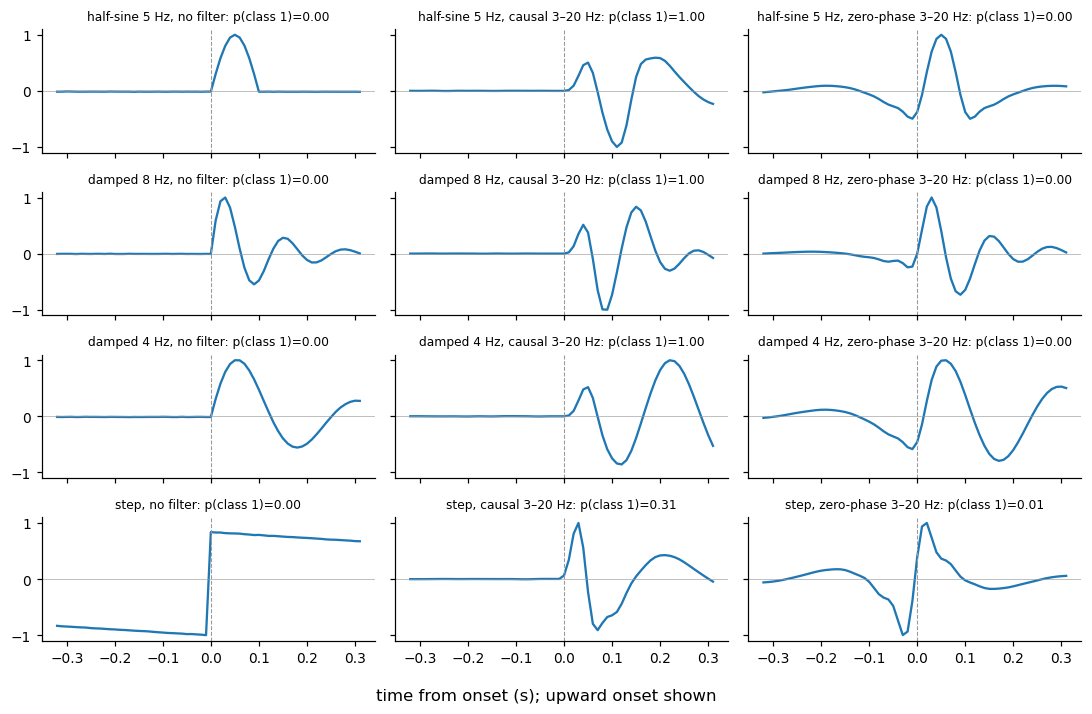

p(class 1) | upward onset  \
shape          preprocessing                                   
half-sine 5 Hz no filter                               0.000   
               causal 3–20 Hz                          1.000   
               zero-phase 3–20 Hz                      0.000   
damped 8 Hz    no filter                               0.000   
               causal 3–20 Hz                          1.000   
               zero-phase 3–20 Hz                      0.000   
damped 4 Hz    no filter                               0.000   
               causal 3–20 Hz                          1.000   
               zero-phase 3–20 Hz                      0.000   
step           no filter                               0.001   
               causal 3–20 Hz                          0.312   
               zero-phase 3–20 Hz                      0.013   

                                   p(class 1) | downward onset  
shape          preprocessing                                    
half-sine 5 Hz no filter                                   1.0  
               causal 3–20 Hz                              0.0  
               zero-phase 3–20 Hz                          1.0  
damped 8 Hz    no filter                                   1.0  
               causal 3–20 Hz                              0.0  
               zero-phase 3–20 Hz                          1.0  
damped 4 Hz    no filter                                   1.0  
               causal 3–20 Hz                              0.0  
               zero-phase 3–20 Hz                          1.0  
step           no filter                                   1.0  
               causal 3–20 Hz                              1.0  
               zero-phase 3–20 Hz                          1.0

In [3]:
t = np.arange(500.); P = 300
shapes = {'half-sine 5 Hz': lambda u: np.where(u < 10, np.sin(np.pi * u / 10), 0),
          'damped 8 Hz': lambda u: np.sin(2 * np.pi * 8 * u / 100) * np.exp(-u / 10),
          'damped 4 Hz': lambda u: np.sin(2 * np.pi * 4 * u / 100) * np.exp(-u / 20),
          'step': lambda u: np.ones_like(u)}
prep = {'no filter': lambda W: E.bandpass(W, 100., None, None),
        'causal 3–20 Hz': lambda W: E.bandpass(W, 100., 3, 20, zero_phase=False),
        'zero-phase 3–20 Hz': lambda W: E.bandpass(W, 100., 3, 20, zero_phase=True)}
rng = np.random.default_rng(0)
rows = []
fig, axs = plt.subplots(len(shapes), 3, figsize=(10, 6.5), sharex=True, sharey=True)
for i, (sname, f) in enumerate(shapes.items()):
    w = np.where(t >= P, f(t - P), 0.) + 1e-3 * rng.standard_normal(len(t))
    for j, (pname, pf) in enumerate(prep.items()):
        Wp = E.crop(pf(np.stack([w, -w])), P)
        o = A.predict(model, Wp)
        rows.append((sname, pname, round(float(o['p_up'][0]), 3), round(float(o['p_up'][1]), 3)))
        tt = (np.arange(64) - 32) / 100
        axs[i, j].plot(tt, Wp[0] / np.abs(Wp[0]).max(), color=UP)
        axs[i, j].axvline(0, color=GREY, ls='--', lw=.7); axs[i, j].axhline(0, color=GREY, lw=.4)
        axs[i, j].set_title(f"{sname}, {pname}: p(class 1)={o['p_up'][0]:.2f}", fontsize=8)
fig.supxlabel('time from onset (s); upward onset shown'); fig.tight_layout(); plt.show()
pd.DataFrame(rows, columns=['shape', 'preprocessing', 'p(class 1) | upward onset', 'p(class 1) | downward onset']).set_index(['shape', 'preprocessing'])

**Result.** For the pulse-like onsets, a causal band-pass gives the expected answer (upward onset → class 1 with p ≈ 1).
A zero-phase band-pass, or no filter at all, inverts it with the same confidence. The step is ambiguous after causal filtering.
The model therefore appears to have been trained on causally filtered waveforms, and it is not robust to the filter phase:
it reads the shape of the first lobes, and a zero-phase filter adds an opposite-sign precursor before the onset (section 4a).

Station metadata is not involved: all Axial Z channels have dip −90° and positive sensitivity, with no negative stage gains (next cell).

In [4]:
from obspy import read_inventory
inv = read_inventory(f'{REPO}/workflow/05_magnitude/station_inventory_v2.xml').select(network='OO', station='AX*')
rows = []
for s in inv[0]:
    for c in s:
        if c.code in ('EHZ', 'HHZ'):
            gains = [st.stage_gain for st in c.response.response_stages if st.stage_gain is not None]
            rows.append((s.code, c.code, c.sample_rate, c.dip, c.response.instrument_sensitivity.value,
                         sum(g < 0 for g in gains)))
pd.DataFrame(rows, columns=['station', 'channel', 'sr (Hz)', 'dip', 'sensitivity', 'negative stage gains'])

,station,channel,sr (Hz),dip,sensitivity,negative stage gains
0,AXAS1,EHZ,200.0,-90.0,834873000.0,0
1,AXAS2,EHZ,200.0,-90.0,836380000.0,0
2,AXBA1,HHZ,200.0,-90.0,907953000.0,0
3,AXCC1,HHZ,200.0,-90.0,924704000.0,0
4,AXEC1,EHZ,200.0,-90.0,835975000.0,0
5,AXEC2,HHZ,200.0,-90.0,924605000.0,0
6,AXEC3,EHZ,200.0,-90.0,835394000.0,0
7,AXID1,EHZ,200.0,-90.0,836671000.0,0


## 3. Data: v4 P picks at Axial

`workflow/09_polarity/axial_test_extract.py` sampled 24 days (2014-11 to 2016, stratified before / during / after the
April 2015 eruption) and up to 150 P picks per station-day. Each station-day was read once from pnwstore (EHZ at 200 Hz for
AXAS1/AS2/EC1/EC3/ID1, HHZ for AXCC1/EC2 and for AXBA1, which is **not** in the FM_ML training set),
decimated to 100 Hz with a zero-phase FIR anti-alias filter (flat in 3–20 Hz), and a 5 s window (−3 s to +2 s around the pick) stored in counts.

From here on the model input is the **causal** 3–20 Hz trace (`XM`), since section 2 and section 4 show that this is the
setting under which the model's labels mean what they say. The zero-phase trace (`XF`) is kept for comparison.

In [5]:
X, sr, pi, meta = E.load_windows(DATA)
meta['day'] = pd.to_datetime(meta.pick_time).dt.date
print(f'{len(X)} windows, {meta.day.nunique()} days, sr {sr} Hz, P at sample {pi}')
meta.groupby(['station', 'channel']).size().rename('windows').to_frame().T

12071 windows, 24 days, sr 100.0 Hz, P at sample 300


station,AXAS1,AXAS2,AXBA1,AXCC1,AXEC1,AXEC2,AXEC3,AXID1
channel,EHZ,EHZ,HHZ,HHZ,EHZ,HHZ,EHZ,EHZ
windows,1875,1690,104,1670,1913,1722,1924,1173


In [6]:
XC = E.bandpass(X, sr, 3, 20, zero_phase=False)   # causal: no energy before the onset
XF = E.bandpass(X, sr, 3, 20, zero_phase=True)    # zero-phase (MATLAB filtfilt-like)
XM = XC                                           # model input from here on
def run(XX, shift=0):
    o = A.predict(model, E.crop(XX, pi, shift=shift))
    o['cls1'] = np.where(o['p_up'] > .5, 1, -1)
    o['kept'] = (o['confidence'] >= .8) & (E.entropy(o['p_up']) <= .2)
    return o
out, out_zp = run(XM), run(XF)
meta['p1'] = out['p_up']; meta['conf'] = out['confidence']; meta['kept'] = out['kept']; meta['cls1'] = out['cls1']
meta['cls1_zp'] = out_zp['cls1']; meta['kept_zp'] = out_zp['kept']
meta['snr'] = E.snr_db(XC, pi, sr)
fm, onset = E.first_motion_sign(XC, pi, sr, k=4, search=(-0.1, 0.25))
meta['fm'] = fm; meta['onset'] = onset
fm_zp, onset_zp = E.first_motion_sign(XF, pi, sr, k=4, search=(-0.1, 0.25))   # same rule on the zero-phase trace
meta['fm_zp'] = fm_zp
print(f"causal input: kept (conf>=0.8 & entropy<=0.2) {meta.kept.mean():.0%}; class 1 among kept {(meta.cls1[meta.kept] == 1).mean():.0%}")
print(f"zero-phase input and causal input give the same class for {np.mean(meta.cls1 == meta.cls1_zp):.0%} of picks")
print(f"automatic first motion found: {(meta.fm != 0).mean():.0%}; median SNR {meta.snr.median():.1f} dB (causal 3-20 Hz)")

causal input: kept (conf>=0.8 & entropy<=0.2) 78%; class 1 among kept 61%
zero-phase input and causal input give the same class for 32% of picks
automatic first motion found: 93%; median SNR 17.7 dB (causal 3-20 Hz)


### Example windows

Random kept picks with SNR > 15 dB, as the model sees them (causal 3–20 Hz, ±0.32 s, normalised).
Colour = automatic first motion (blue up, red down, grey none); title = model p(class 1) with causal input / zero-phase input.

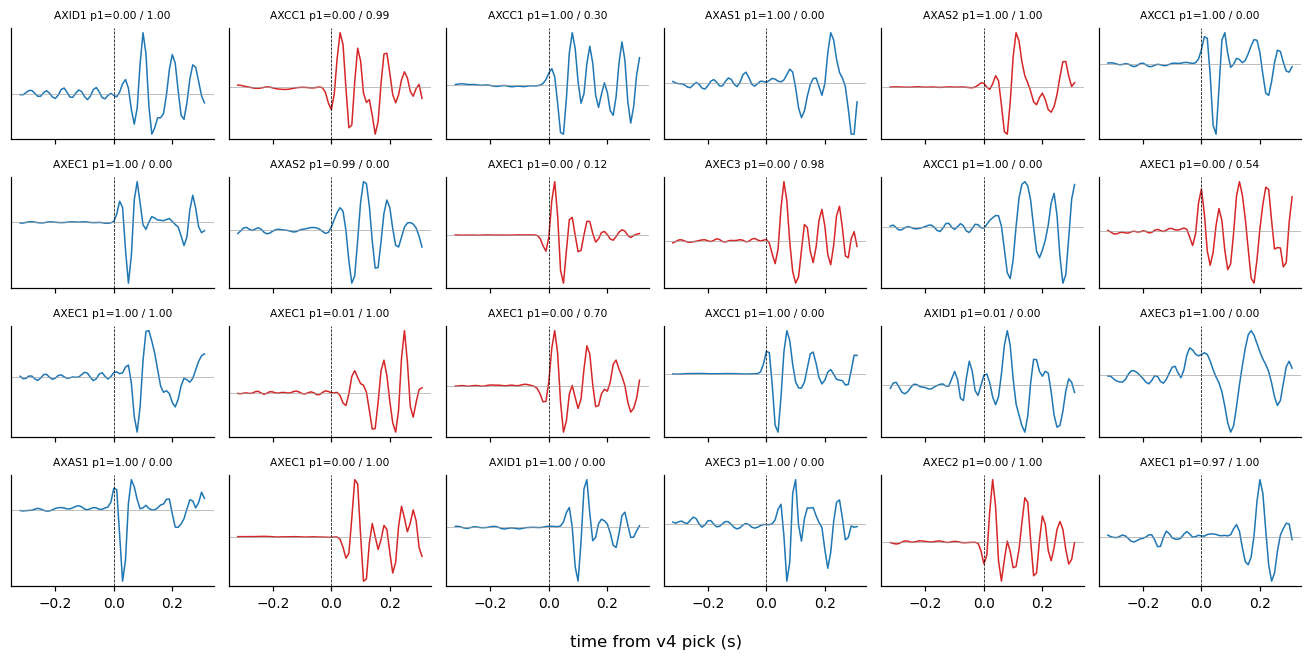

In [7]:
rng = np.random.default_rng(0)
idx = rng.choice(np.flatnonzero(meta.kept & (meta.snr > 15)), 24, replace=False)
fig, axs = plt.subplots(4, 6, figsize=(12, 6), sharex=True)
tt = (np.arange(64) - 32) / sr
for a, i in zip(axs.flat, idx):
    w = E.crop(XM[i], pi); w = w / np.abs(w).max()
    a.plot(tt, w, color={1: UP, -1: DOWN, 0: GREY}[meta.fm[i]], lw=1)
    a.axvline(0, color='k', lw=.5, ls='--'); a.axhline(0, color=GREY, lw=.4)
    a.set_title(f"{meta.station[i]} p1={meta.p1[i]:.2f} / {out_zp['p_up'][i]:.2f}", fontsize=7); a.set_yticks([])
fig.supxlabel('time from v4 pick (s)'); fig.tight_layout(); plt.show()

## 4. Issue 1 on real data

### 4a. Why: a zero-phase filter puts an opposite-sign lobe before the onset

An impulsive onset filtered with a two-pass (zero-phase) band-pass gets a small precursor of the **opposite** sign before the
true onset. Anyone, or any rule, reading "the first wiggle" on the zero-phase trace reads the precursor. One high-SNR pick, filtered both ways:

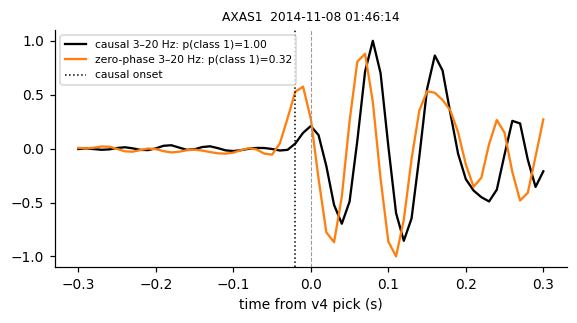

In [8]:
i = int(np.flatnonzero((meta.snr > 30) & (meta.fm != 0) & (meta.fm_zp == -meta.fm))[0])
tt = (np.arange(pi - 30, pi + 31) - pi) / sr
fig, ax = plt.subplots(figsize=(6, 2.8))
for tr, lab, col in ((XC[i], f'causal 3–20 Hz: p(class 1)={meta.p1[i]:.2f}', 'k'),
                     (XF[i], f"zero-phase 3–20 Hz: p(class 1)={out_zp['p_up'][i]:.2f}", '#ff7f0e')):
    w = tr[pi - 30:pi + 31]; ax.plot(tt, w / np.abs(w).max(), color=col, label=lab)
ax.axvline(0, color=GREY, ls='--', lw=.7); ax.axvline(meta.onset[i] / sr, color='k', ls=':', lw=1, label='causal onset')
ax.set_xlabel('time from v4 pick (s)'); ax.set_title(f"{meta.station[i]}  {str(meta.pick_time[i])[:19]}", fontsize=8)
ax.legend(fontsize=7); plt.show()

### 4b. Agreement with the first-motion reference, causal vs zero-phase model input

Fraction of kept picks where the model's class 1 coincides with an **upward** automatic first motion (causal reference).
Values near 1 mean class 1 = up; near 0 mean class 1 = down.

/tmp/ipykernel_3982800/4011144868.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = d.groupby('snr_bin', observed=True).apply(agree)


,n (causal input),"class 1 = up, causal input",n (zero-phase input),"class 1 = up, zero-phase input"
snr_bin,,,,
"(-inf, 5.0]",91.0,0.46,82.0,0.50
"(5.0, 10.0]",964.0,0.41,968.0,0.56
"(10.0, 15.0]",1725.0,0.42,1738.0,0.47
"(15.0, 20.0]",1770.0,0.72,1735.0,0.30
"(20.0, 30.0]",2659.0,0.87,2435.0,0.26
"(30.0, inf]",1617.0,0.88,1470.0,0.24


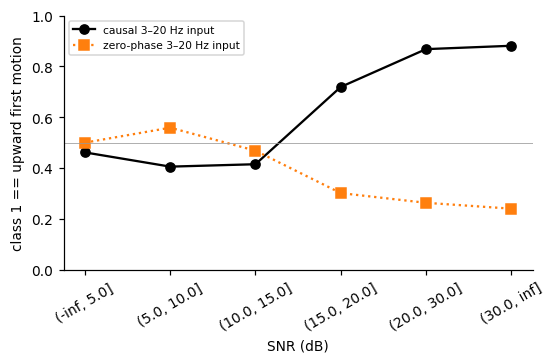

In [9]:
bins = [-np.inf, 5, 10, 15, 20, 30, np.inf]
d = meta.copy(); d['snr_bin'] = pd.cut(d.snr, bins)
def agree(g):
    a = g[(g.fm != 0) & g.kept]; b = g[(g.fm != 0) & g.kept_zp]
    return pd.Series({'n (causal input)': len(a), 'class 1 = up, causal input': (a.cls1 == a.fm).mean(),
                      'n (zero-phase input)': len(b), 'class 1 = up, zero-phase input': (b.cls1_zp == b.fm).mean()})
tab = d.groupby('snr_bin', observed=True).apply(agree)
display(tab.round(2))
fig, ax = plt.subplots(figsize=(5.5, 3))
x = range(len(tab))
ax.plot(x, tab['class 1 = up, causal input'], 'o-', color='k', label='causal 3–20 Hz input')
ax.plot(x, tab['class 1 = up, zero-phase input'], 's:', color='#ff7f0e', label='zero-phase 3–20 Hz input')
ax.axhline(.5, color=GREY, lw=.5); ax.set_ylim(0, 1); ax.set_xticks(list(x)); ax.set_xticklabels([str(b) for b in tab.index], rotation=30)
ax.set_xlabel('SNR (dB)'); ax.set_ylabel('class 1 == upward first motion'); ax.legend(fontsize=7); plt.show()

### 4c. Stacks by predicted class (causal input, causal trace)

Mean of the normalised windows of high-SNR kept picks grouped by the model's class. Class 1 should go up at the onset.

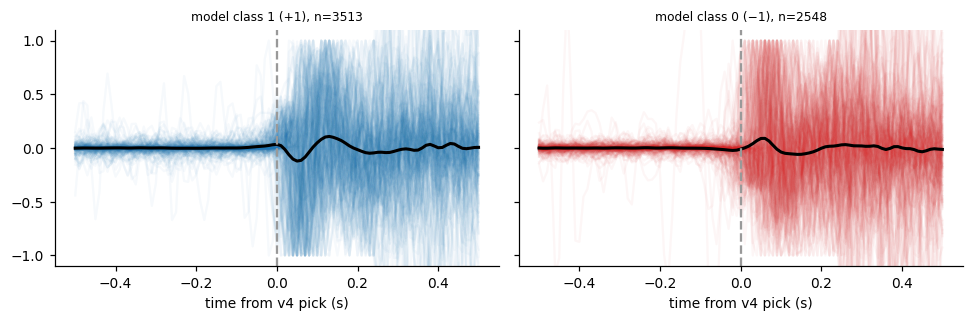

In [10]:
sel = meta.kept & (meta.snr > 15)
tt = (np.arange(-50, 51)) / sr
fig, axs = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for a, c, col in zip(axs, (1, -1), (UP, DOWN)):
    W = XC[sel & (meta.cls1 == c), pi - 50:pi + 51]
    W = W / np.abs(W[:, 45:75]).max(1, keepdims=True)
    a.plot(tt, W[:200].T, color=col, alpha=.04); a.plot(tt, W.mean(0), color='k', lw=2)
    a.axvline(0, color=GREY, ls='--'); a.set_ylim(-1.1, 1.1); a.set_xlabel('time from v4 pick (s)')
    a.set_title(f'model class {"1 (+1)" if c > 0 else "0 (−1)"}, n={len(W)}', fontsize=8)
fig.tight_layout(); plt.show()

## 5. Issue 2 — high confidence on pure noise

Causal-input model applied to 64-sample windows centred 1.5 s **before** the P pick (pre-event noise, no P wave).
A calibrated classifier should be uncertain here.

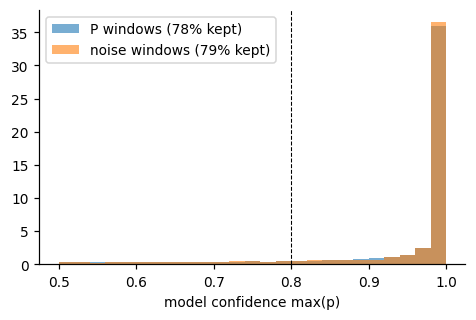

noise windows: mean confidence 0.95, kept 79%, class 1 63%
P windows with SNR < 5 dB: n=564, kept 76%


In [11]:
noise = run(XM, shift=-150)
fig, ax = plt.subplots(figsize=(5, 3))
b = np.linspace(.5, 1, 26)
ax.hist(meta.conf, b, alpha=.6, label=f'P windows ({meta.kept.mean():.0%} kept)', density=True)
ax.hist(noise['confidence'], b, alpha=.6, label=f"noise windows ({noise['kept'].mean():.0%} kept)", density=True)
ax.axvline(.8, color='k', ls='--', lw=.7); ax.set_xlabel('model confidence max(p)'); ax.legend(); plt.show()
print(f"noise windows: mean confidence {noise['confidence'].mean():.2f}, kept {noise['kept'].mean():.0%}, class 1 {np.mean(noise['cls1'] == 1):.0%}")
lo = meta.snr < 5
print(f"P windows with SNR < 5 dB: n={lo.sum()}, kept {meta.kept[lo].mean():.0%}")

## 6. Issue 3 — pick-time sensitivity

FM_ML trained with time shifts of N(0, 0.02 s) clipped at ±0.08 s around analyst picks (the training templates also carry a
per-station `DDt` offset whose use is not documented). Our v4 picks come from the ML picker ensemble. (a) Where the automatic
onset falls relative to the v4 pick; (b) how often the predicted class changes when the window moves by k samples (k > 0 = pick k samples late).

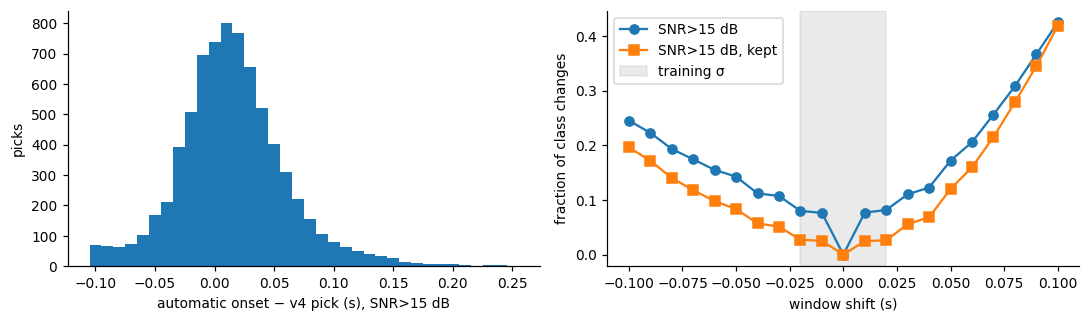

median onset - pick (SNR>15): 10 ms


In [12]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].hist(meta.onset[meta.snr > 15].dropna() / sr, np.arange(-0.105, 0.26, 0.01))
axs[0].set_xlabel('automatic onset − v4 pick (s), SNR>15 dB'); axs[0].set_ylabel('picks')
shifts = np.arange(-10, 11)
flip = []
for k in shifts:
    c = run(XM, shift=k)['cls1']
    flip.append([np.mean(c[m] != meta.cls1[m]) for m in (meta.snr > 15, meta.kept & (meta.snr > 15))])
flip = np.array(flip)
axs[1].plot(shifts / sr, flip[:, 0], 'o-', label='SNR>15 dB'); axs[1].plot(shifts / sr, flip[:, 1], 's-', label='SNR>15 dB, kept')
axs[1].axvspan(-.02, .02, color=GREY, alpha=.2, label='training σ'); axs[1].set_xlabel('window shift (s)')
axs[1].set_ylabel('fraction of class changes'); axs[1].legend(); fig.tight_layout(); plt.show()
print(f"median onset - pick (SNR>15): {np.nanmedian(meta.onset[meta.snr > 15]) / sr * 1000:.0f} ms")

In [13]:
# Re-centre each window on the automatic onset instead of the v4 pick.
ok = meta.onset.notna() & (meta.snr > 15) & (meta.fm != 0)
Wc = np.stack([E.crop(XM[i], pi, shift=int(meta.onset[i])) for i in np.flatnonzero(ok)])
c_on = np.where(A.predict(model, Wc)['p_up'] > .5, 1, -1)
print(f"SNR>15 dB, n={ok.sum()}: class 1 == up first motion  at v4 pick {np.mean(meta.cls1[ok] == meta.fm[ok]):.2f}"
      f"  |  re-centred on the automatic onset {np.mean(c_on == meta.fm[ok].values):.2f}")

SNR>15 dB, n=7384: class 1 == up first motion  at v4 pick 0.77  |  re-centred on the automatic onset 0.79


## 7. Issue 4 — other preprocessing choices not pinned down

Filter order and band are not in the repo, and the repo is inconsistent about the sampling rate: the h5 pipeline that produced
this model is 100 Hz (±0.32 s), while `CLAUDE.md` and the real-time integration plan describe 200 Hz windows (64 samples = ±0.16 s).
Relative to the reference setting (causal 3–20 Hz, order 4, 100 Hz):

In [14]:
variants = {
    'causal 3–20 Hz o4, 100 Hz (reference)': lambda: XM,
    'causal 3–20 Hz o2': lambda: E.bandpass(X, sr, 3, 20, order=2, zero_phase=False),
    'causal 1–20 Hz o4': lambda: E.bandpass(X, sr, 1, 20, zero_phase=False),
    'causal 2–30 Hz o4': lambda: E.bandpass(X, sr, 2, 30, zero_phase=False),
    'zero-phase 3–20 Hz o4': lambda: XF,
    'no filter (detrend only)': lambda: E.bandpass(X, sr, None, None),
}
hi = (meta.snr > 15) & (meta.fm != 0)
rows = []
for name, f in variants.items():
    o = run(f())
    rows.append((name, np.mean(o['cls1'] == meta.cls1), o['kept'].mean(), np.mean(o['cls1'][hi & o['kept']] == meta.fm[hi & o['kept']])))
o = A.predict(model, E.as_200hz_reading(XM, pi)); c = np.where(o['p_up'] > .5, 1, -1)
k = (o['confidence'] >= .8) & (E.entropy(o['p_up']) <= .2)
rows.append(('causal 3–20 Hz, read as 200 Hz (±0.16 s)', np.mean(c == meta.cls1), k.mean(), np.mean(c[hi & k] == meta.fm[hi & k])))
pd.DataFrame(rows, columns=['preprocessing', 'same class as reference', 'kept',
                           'class 1 = up first motion (SNR>15, kept)']).set_index('preprocessing').round(2)

,same class as reference,kept,"class 1 = up first motion (SNR>15, kept)"
preprocessing,,,
"causal 3–20 Hz o4, 100 Hz (reference)",1.00,0.78,0.83
causal 3–20 Hz o2,0.69,0.76,0.74
causal 1–20 Hz o4,0.58,0.77,0.59
causal 2–30 Hz o4,0.72,0.76,0.79
zero-phase 3–20 Hz o4,0.32,0.75,0.27
no filter (detrend only),0.53,0.76,0.52
"causal 3–20 Hz, read as 200 Hz (±0.16 s)",0.65,0.83,0.69


## 8. Per-station breakdown (causal input)

AXBA1 (broadband HHZ) was not in the training set.

In [15]:
g = meta.groupby('station')
st = pd.DataFrame({'n': g.size(), 'median SNR': g.snr.median(), 'kept': g.kept.mean(),
                   'class 1 (kept)': g.apply(lambda x: (x.cls1[x.kept] == 1).mean()),
                   'class 1 = up FM (SNR>15, kept)': g.apply(lambda x: (x.cls1 == x.fm)[x.kept & (x.snr > 15) & (x.fm != 0)].mean()),
                   'n (SNR>15, kept, FM)': g.apply(lambda x: (x.kept & (x.snr > 15) & (x.fm != 0)).sum()),
                   'noise kept': pd.Series(noise['kept']).groupby(meta.station).mean()})
st.round(2)

/tmp/ipykernel_3982800/549676828.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  'class 1 (kept)': g.apply(lambda x: (x.cls1[x.kept] == 1).mean()),
/tmp/ipykernel_3982800/549676828.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  'class 1 = up FM (SNR>15, kept)': g.apply(lambda x: (x.cls1 == x.fm)[x.kept & (x.snr > 15) & (x.fm != 0)].mean()),
/tmp/ipykernel_3982800/549676828.py:5: FutureWarning: DataFrameGroup

,n,median SNR,kept,class 1 (kept),"class 1 = up FM (SNR>15, kept)","n (SNR>15, kept, FM)",noise kept
station,,,,,,,
AXAS1,1875,16.11,0.84,0.77,0.87,934,0.79
AXAS2,1690,17.63,0.72,0.56,0.73,763,0.79
AXBA1,104,5.24,0.74,0.71,0.70,10,0.85
AXCC1,1670,20.71,0.88,0.76,0.91,1082,0.80
AXEC1,1913,19.55,0.77,0.48,0.84,1044,0.79
AXEC2,1722,17.84,0.80,0.51,0.84,901,0.79
AXEC3,1924,17.10,0.72,0.51,0.76,855,0.80
AXID1,1173,15.20,0.74,0.63,0.78,457,0.79


## 9. Summary of issues (to discuss with Maochuan)

Numbers are from the 12,071 v4 P windows at the eight Axial stations in this notebook. The reference is an automatic
first motion, not analyst labels, so the agreement values are lower bounds at high SNR and not meaningful below about 15 dB.

| # | Issue | Evidence | Consequence for catalog v4 |
|---|---|---|---|
| 1 | **The output sign depends on the band-pass phase.** Causal 3–20 Hz input → class 1 = up. Zero-phase input, or no filter → class 1 = down, with the same confidence. | Synthetic onsets (section 2): p(class 1) 1.00 vs 0.00. Real data above 20 dB (4b): class 1 = up 0.87–0.88 with causal input, 0.24–0.26 with zero-phase input. The two inputs give the same class for only 32 % of picks. | The manuscript text ("bandpass filtered between 3 and 20 Hz") does not say causal. Anyone using `filtfilt`, MATLAB `bandpass()` (zero-phase), or ObsPy `filter(..., zerophase=True)` gets inverted polarities. We use causal order-4 Butterworth until the training filter is confirmed. |
| 2 | **Confident on pure noise.** | Pre-event noise windows: mean confidence 0.95; 79 % pass conf ≥ 0.8 and entropy ≤ 0.2. P windows below 5 dB SNR: 76 % pass. | The confidence threshold is not a quality filter. We need an SNR gate (≥ 15–20 dB on the causal trace) and a recalibration, or a model with an "unknown" class. |
| 3 | **No measurable skill at 5–15 dB.** | Agreement with the automatic reference is 0.41–0.46 at 5–15 dB, rising to 0.72 at 15–20 dB and 0.87–0.88 above 20 dB. | Part of this is the reference failing at low SNR. We cannot tell which without analyst labels. Most v4 picks are in this range (median SNR 17.7 dB here). |
| 4 | **Sensitive to the exact filter, not only its phase.** | Relative to causal 3–20 Hz order 4: order 2 changes 31 % of classes, 1–20 Hz changes 42 %, 2–30 Hz changes 28 %. Agreement drops from 0.83 to 0.59–0.79. | The filter design (type, order, corners, before or after resampling) must be copied exactly from training. |
| 5 | **Sampling rate is ambiguous in the repo.** | The h5 pipeline is 100 Hz (±0.32 s). `CLAUDE.md` and the real-time plan describe 200 Hz windows (±0.16 s). Reading our windows as 200 Hz changes 35 % of classes. | Confirm 100 Hz for `PolarPicker_h5_20260308_154910`. |
| 6 | **Pick-time sensitivity is moderate.** | The automatic onset is a median 10 ms after the v4 pick (spread about ±40 ms). Class changes: about 3 % at ±10–20 ms, 8–12 % at ±50 ms, 20–42 % at ±0.1 s (kept, SNR > 15; late windows are worse than early ones). Re-centring on the onset raises agreement from 0.77 to 0.79. | Acceptable for most picks. The per-station `DDt` offset stored with the training templates is undocumented; if the training windows were centred on pick + DDt, our centring differs. |
| 7 | **Station differences.** | Agreement at SNR > 15 dB, kept: AXCC1 0.91, AXAS1 0.87, AXEC1/EC2 0.84, AXID1 0.78, AXEC3 0.76, AXAS2 0.73. AXBA1 (not in training) has only 10 usable picks. | Per-station accuracy and possible station-specific bias need analyst labels. |

**Station metadata is fine.** All Axial Z channels have dip −90°, positive sensitivity and no negative stage gains, so none of the
above comes from instrument polarity.

### Questions for Maochuan
1. Exactly how were the training waveforms filtered: function, Butterworth order, corners, one-pass (`filter`) or two-pass (`filtfilt` / MATLAB `bandpass()`), and before or after resampling from 200 to 100 Hz?
2. Label convention: is `Po_{STA}` = +1 an upward first motion on the raw Z counts? Were the manual polarities read on raw or filtered traces?
3. Were the 2 s templates centred on the analyst pick or on pick + `DDt_{STA}`?
4. Is `PolarPicker_h5_20260308_154910` definitely 100 Hz input (the docs mention 200 Hz in places)?
5. Can we use the 2015 Axial manual polarities (the `Felix` struct) as a benchmark? They overlap in time with our v4 Axial picks, which would turn this consistency check into a true accuracy.
6. Can we have the original `PolarCAP.h5` weights and a license for the FM_ML weights?

### Next steps on our side
- Keep causal 3–20 Hz, order 4, 100 Hz as the working preprocessing; switch if the answer to Q1 differs.
- Match v4 Axial picks to the manual labels (Q5) and report accuracy versus SNR, pick probability and station.
- Add an SNR gate and recalibrate confidence on the labelled set before any off-Axial use (Cascadia Initiative OBS, land).